\
# 05. コミュニティ検出・階層粗視化・クラスタ配置・DAG レイアウト

このノートブックでは、`egraph` v6 における **コミュニティ検出・クラスタリング（ゼロコピー Result クラス 5 種）**、**階層粗視化と座標延長**、**Group-in-a-Box / Treemap 配置**、**クラスタ配置リファインメント**、および **有向非巡回グラフ（DAG）の閉路除去・推移簡約 (`transitive_reduction`)・階層化・分離制約射影** を網羅します。

- **コミュニティ検出**: `louvain_communities` (`LouvainResult`), `leiden_communities` (`LeidenResult`), `label_propagation` (`LabelPropagationResult`), `spectral_clustering` (`SpectralClusteringResult`), `kmeans_plus_plus` (`KMeansResult`)
- **粗視化・延長・重心整合**: `coarsen_graph`, `louvain_coarsen`, `project_clustered_layout`, `project_clustered_layout_with_radii`, `align_clustered_centroids`
- **Group-in-a-Box・Treemap**: `squarified_treemap`, `GroupInABoxSolver`
- **クラスタ配置リファイン**: `ClusterRefineSolver`, `refine_cluster_layout`
- **DAG 閉路除去・推移簡約・階層割り当て・制約射影**: `generate_layered_dag`, `cycle_edges`, `remove_cycles`, `transitive_reduction`, `assign_layers`, `generate_layered_constraints`, `SeparationConstraint`, `project_1d`, `project_layout_axis`

> `egraph` はレイアウト・クラスタ・制約計算のみに使用し、描画はすべて `matplotlib`（`LineCollection`, `Rectangle`, `FancyArrowPatch` 等）および `networkx` で行います。

In [ ]:
!pip install -q --pre "egraph==6.0.0a8" matplotlib-fontja

## 1. インポートとクラスタ／ボックス／DAG 描画ヘルパーの定義

クラスタ別に色分けしたグラフ描画、Group-in-a-Box の矩形ボックス描画、および `FancyArrowPatch` と `ax.invert_yaxis()` を用いた上→下向きの DAG 描画ヘルパーを準備します。

In [ ]:
\
import time
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt
from matplotlib.collections import LineCollection
from matplotlib.patches import FancyArrowPatch, Rectangle

try:
    import matplotlib_fontja  # noqa: F401
except ImportError:
    pass

import egraph as eg

plt.rcParams["figure.dpi"] = 120


def plot_clustered_graph(
    graph: eg.CsrGraph,
    layout: eg.Layout2d,
    labels: np.ndarray,
    ax,
    title: str = "",
    node_size: float = 28.0,
):
    '''Plot clustered 2D layout distinguishing intra-cluster vs inter-cluster edges.'''
    coords = layout.coords(copy=False)
    indptr, indices = graph.indptr(), graph.indices()
    intra_segs, inter_segs = [], []
    for u in range(graph.num_nodes):
        for v in indices[int(indptr[u]) : int(indptr[u + 1])]:
            v_int = int(v)
            if graph.is_directed or u < v_int:
                if labels[u] == labels[v_int]:
                    intra_segs.append([coords[u], coords[v_int]])
                else:
                    inter_segs.append([coords[u], coords[v_int]])
    if inter_segs:
        ax.add_collection(LineCollection(inter_segs, colors="#bbbbbb", linewidths=0.45, alpha=0.35, zorder=1))
    if intra_segs:
        ax.add_collection(LineCollection(intra_segs, colors="#555555", linewidths=0.7, alpha=0.55, zorder=2))
    cmap = plt.get_cmap("tab10" if len(np.unique(labels)) <= 10 else "tab20")
    ax.scatter(
        coords[:, 0],
        coords[:, 1],
        s=node_size,
        c=labels % cmap.N,
        cmap=cmap,
        edgecolors="white",
        linewidths=0.35,
        zorder=3,
    )
    ax.set_aspect("equal")
    ax.autoscale_view()
    ax.set_xticks([])
    ax.set_yticks([])
    if title:
        ax.set_title(title, fontsize=9.5)


def plot_gib_boxes(
    graph: eg.CsrGraph,
    layout: eg.Layout2d,
    labels: np.ndarray,
    boxes: list[dict],
    ax,
    title: str = "",
    node_size: float = 24.0,
):
    '''Plot Group-in-a-Box layout with bounding rectangles via matplotlib.patches.Rectangle.'''
    cmap = plt.get_cmap("tab10")
    for b in boxes:
        cid = int(b["cluster_id"])
        rect = Rectangle(
            (b["x_min"], b["y_min"]),
            b["x_max"] - b["x_min"],
            b["y_max"] - b["y_min"],
            facecolor=cmap(cid % 10),
            alpha=0.10,
            edgecolor=cmap(cid % 10),
            linewidth=1.2,
            zorder=0,
        )
        ax.add_patch(rect)
    plot_clustered_graph(graph, layout, labels, ax, title=title, node_size=node_size)
    ax.autoscale_view()


def plot_dag_layered(
    graph: eg.CsrGraph,
    layout: eg.Layout2d,
    layers: np.ndarray,
    ax,
    title: str = "",
):
    '''Plot layered directed graph with FancyArrowPatch and inverted Y axis (layer 0 at top).'''
    coords = layout.coords(copy=False)
    indptr, indices = graph.indptr(), graph.indices()
    cmap = plt.get_cmap("viridis")
    max_layer = max(1, int(layers.max()))
    for u in range(graph.num_nodes):
        for v in indices[int(indptr[u]) : int(indptr[u + 1])]:
            v_int = int(v)
            arrow = FancyArrowPatch(
                coords[u],
                coords[v_int],
                arrowstyle="-|>",
                mutation_scale=11,
                linewidth=1.0,
                color="#555555",
                alpha=0.75,
                shrinkA=9,
                shrinkB=9,
                zorder=1,
            )
            ax.add_patch(arrow)
    ax.scatter(
        coords[:, 0],
        coords[:, 1],
        s=260,
        c=layers / max_layer,
        cmap=cmap,
        edgecolors="#222222",
        linewidths=0.9,
        zorder=2,
    )
    for u in range(graph.num_nodes):
        ax.text(
            coords[u, 0],
            coords[u, 1],
            f"{u}\n(L{layers[u]})",
            ha="center",
            va="center",
            fontsize=7.5,
            color="white" if layers[u] <= max_layer * 0.6 else "black",
            fontweight="bold",
            zorder=3,
        )
    ax.autoscale_view()
    ax.invert_yaxis()
    ax.set_xticks([])
    ax.set_yticks([])
    if title:
        ax.set_title(title, fontsize=9.5)


g_karate = eg.load_dataset("karate")
g_lesmis = eg.load_dataset("lesmis")
g_dwt = eg.load_dataset("dwt_1005")
print(f"Loaded karate=({g_karate.num_nodes}, {g_karate.num_edges}), lesmis=({g_lesmis.num_nodes}, {g_lesmis.num_edges}), dwt_1005=({g_dwt.num_nodes}, {g_dwt.num_edges})")

Loaded karate=(34, 78), lesmis=(77, 254), dwt_1005=(1005, 3808)


\
## 2. コミュニティ検出と分割一致度評価（SBM / `karate` / `lesmis`）

`egraph` v6 の 5 つのコミュニティ検出／クラスタリング関数はすべて、ゼロコピーの `.labels` (`NDArray[uint32]`) と型付き統計プロパティを公開する **専用 Result クラス** を返します。

- `louvain_communities` → `LouvainResult` (`.labels`, `.num_communities`, `.modularity`, `.passes`)
- `leiden_communities` → `LeidenResult` (`.labels`, `.num_communities`, `.quality`, `.modularity`, `.passes`)  
  ※ `objective="cpm"` を指定した場合、`.quality` が CPM 目的関数値を、`.modularity` が常に標準モジュラリティ ($\gamma = 1.0$) を返します。
- `label_propagation` → `LabelPropagationResult` (`.labels`, `.num_communities`, `.iterations`, `.converged`)
- `spectral_clustering` → `SpectralClusteringResult` (`.labels`, `.num_clusters`, `.eigen_iterations`)
- `kmeans_plus_plus` → `KMeansResult` (`.labels`, `.centroids`, `.k`, `.dims`, `.inertia`, `.iterations`, `.converged`)

SBM (4 ブロック, N=100) における真値との一致度 (partition_agreement):
手法                            検出数      ARI      AMI
----------------------------------------------------
Louvain                         4   1.0000   1.0000
Leiden (Modularity)             4   1.0000   1.0000
Leiden (CPM, r=0.15)            4   1.0000   1.0000
Label Propagation               4   1.0000   1.0000
Spectral Clustering (k=4)       4   1.0000   1.0000
K-means++ (2D 座標)               4   0.9731   0.9685

karate: Louvain(Q=0.4151, k=4) | Leiden-Mod(Q=0.4198, k=4) | Leiden-CPM(quality=43.10, std_modularity=0.4126, k=5)
lesmis: Leiden-Mod(Q=0.5600, k=6, passes=4) | LPA(iters=5, conv=True) | Spec(eig_iters=1) | KMeans(inertia=53.52)


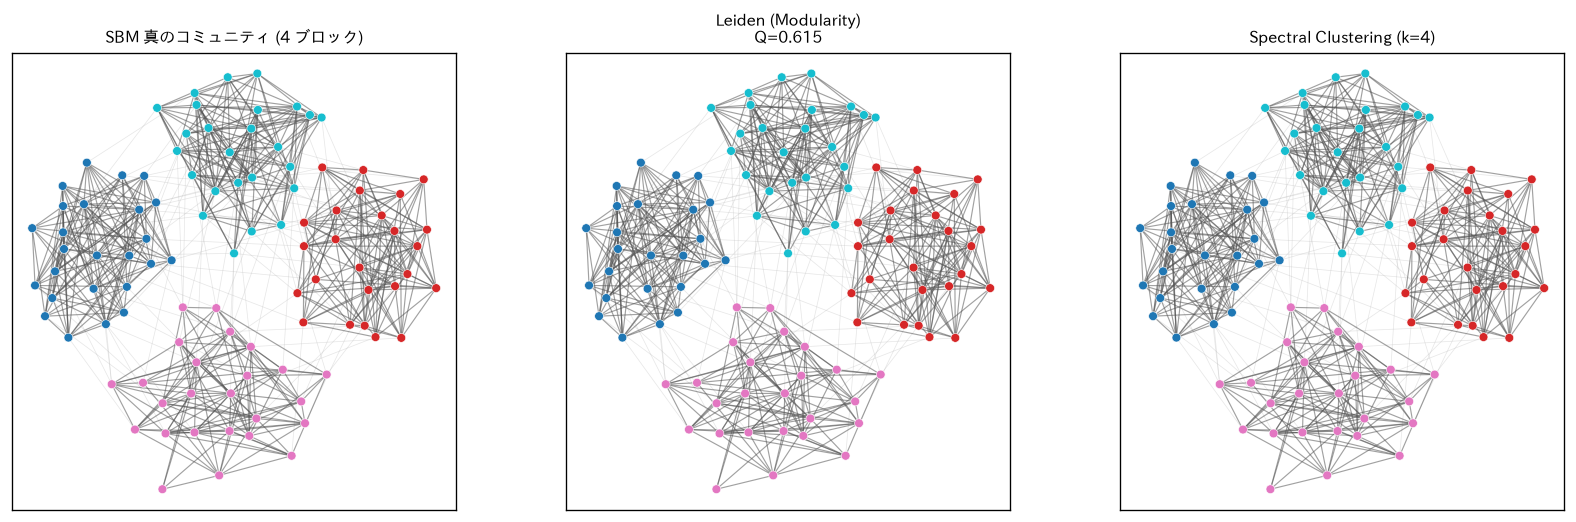

In [ ]:
\
# Build synthetic 4-block SBM (25 nodes per block) via built-in generate_sbm_graph
g_sbm, gt_labels = eg.generate_sbm_graph([25, 25, 25, 25], p_intra=0.45, p_inter=0.02, seed=42)

# Compute a 2D Stress layout for visualization and k-means++ clustering
lay_sbm = eg.Layout2d.init(g_sbm.num_nodes, seed=42)
eg.StressMajorizationSolver.from_graph(g_sbm).run(lay_sbm)

res_louvain = eg.louvain_communities(g_sbm, seed=42)
res_leiden_mod = eg.leiden_communities(g_sbm, objective="modularity", seed=42)
res_leiden_cpm = eg.leiden_communities(g_sbm, objective="cpm", resolution=0.15, seed=42)
res_lpa = eg.label_propagation(g_sbm, seed=42)
res_spec = eg.spectral_clustering(g_sbm, k=4, seed=42)
res_km = eg.kmeans_plus_plus(lay_sbm.coords(copy=False), k=4, n_init=5, seed=42)

methods = [
    ("Louvain", res_louvain.labels),
    ("Leiden (Modularity)", res_leiden_mod.labels),
    ("Leiden (CPM, r=0.15)", res_leiden_cpm.labels),
    ("Label Propagation", res_lpa.labels),
    ("Spectral Clustering (k=4)", res_spec.labels),
    ("K-means++ (2D 座標)", res_km.labels),
]

print("SBM (4 ブロック, N=100) における真値との一致度 (partition_agreement):")
print(f"{'手法':<26} {'検出数':>6} {'ARI':>8} {'AMI':>8}")
print("-" * 52)
for name, pred in methods:
    pa = eg.partition_agreement(gt_labels, pred)
    n_c = len(np.unique(pred))
    print(f"{name:<26} {n_c:>6} {pa['ari']:>8.4f} {pa['ami']:>8.4f}")

# Inspect Result class properties on karate and lesmis
k_lv = eg.louvain_communities(g_karate, seed=42)
k_ld_mod = eg.leiden_communities(g_karate, objective="modularity", seed=42)
k_ld_cpm = eg.leiden_communities(g_karate, objective="cpm", resolution=0.1, seed=42)
lm_ld = eg.leiden_communities(g_lesmis, objective="modularity", seed=42)
print(
    f"\nkarate: Louvain(Q={k_lv.modularity:.4f}, k={k_lv.num_communities}) | "
    f"Leiden-Mod(Q={k_ld_mod.modularity:.4f}, k={k_ld_mod.num_communities}) | "
    f"Leiden-CPM(quality={k_ld_cpm.quality:.2f}, std_modularity={k_ld_cpm.modularity:.4f}, k={k_ld_cpm.num_communities})"
)
print(
    f"lesmis: Leiden-Mod(Q={lm_ld.modularity:.4f}, k={lm_ld.num_communities}, passes={lm_ld.passes}) | "
    f"LPA(iters={res_lpa.iterations}, conv={res_lpa.converged}) | "
    f"Spec(eig_iters={res_spec.eigen_iterations}) | KMeans(inertia={res_km.inertia:.2f})"
)

fig, axes = plt.subplots(1, 3, figsize=(14, 4.4))
plot_clustered_graph(g_sbm, lay_sbm, gt_labels, axes[0], title="SBM 真のコミュニティ (4 ブロック)")
plot_clustered_graph(g_sbm, lay_sbm, res_leiden_mod.labels, axes[1], title=f"Leiden (Modularity)\nQ={res_leiden_mod.modularity:.3f}")
plot_clustered_graph(g_sbm, lay_sbm, res_spec.labels, axes[2], title="Spectral Clustering (k=4)")
plt.tight_layout()
plt.show()

## 3. グラフ粗視化・座標延長・重心整合

大規模グラフの階層レイアウトやクラスタ整合を行うための 5 関数を連携させます。

1. `coarsen_graph(graph, labels)`: 任意の非連続ラベル（例: `[10, 50, ...]`）も自動で `0..K-1` へ詰め直して粗視化グラフを構築
2. `louvain_coarsen`: 多段階 Louvain で指定サイズ以下まで自動粗視化
3. `project_clustered_layout` / `project_clustered_layout_with_radii`: 粗視化座標を元頂点へ延長（一定半径またはクラスタ半径比例ジッタ）
4. `align_clustered_centroids`: 細粒度レイアウトの各クラスタ重心を、指定 `gamma_tether` で粗視化ノード座標へ剛体平行移動で引き寄せる

coarsen_graph (lesmis): 77 -> 7 clusters, coarse_edges=11, sizes=[10, 20, 10, 11, 8, 2, 16]
louvain_coarsen (dwt_1005): num_levels=2, level_clusters=[14, 4], level_res=[1.0, 1.0]
  project_clustered_layout           : finite=True, std=(9.971, 11.578), span=(26.537, 35.674)
  project_clustered_layout_with_radii: finite=True, std=(10.111, 11.620), span=(31.039, 39.393)


align_clustered_centroids mean drift: 10.1086 -> 5.0543 (gamma_tether=0.5)


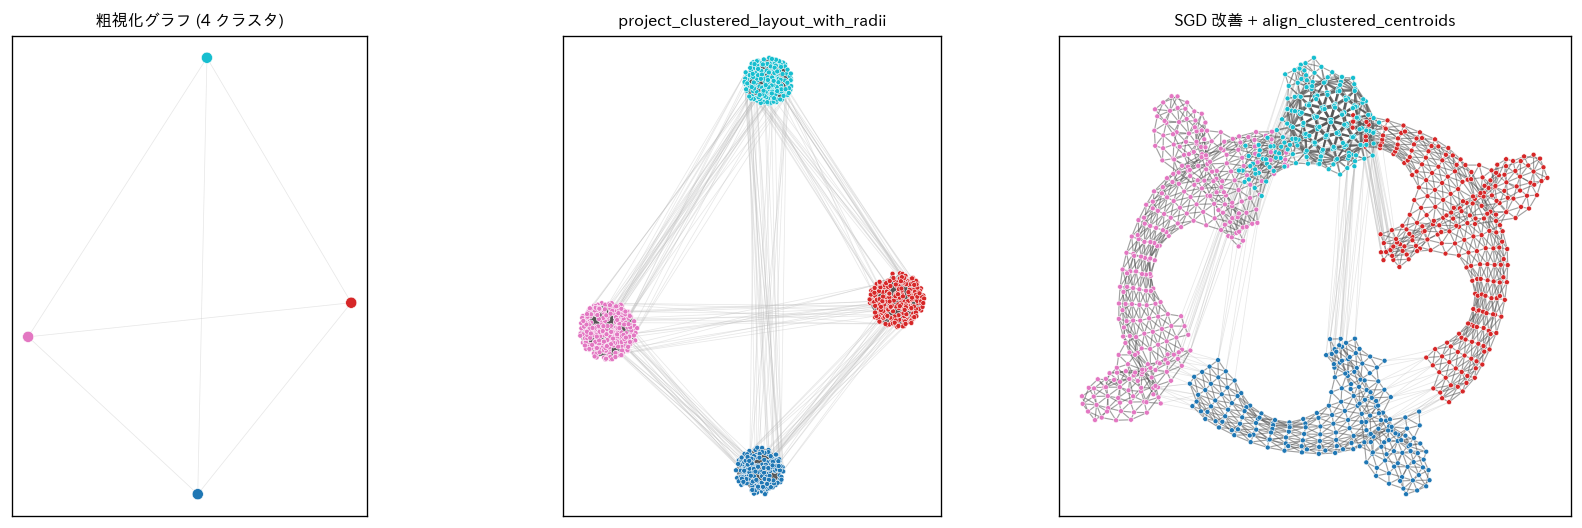

In [ ]:
\
# 1) coarsen_graph compacts arbitrary non-contiguous labels
lv_lm = eg.louvain_communities(g_lesmis, seed=42).labels
sparse_labels = lv_lm * 10 + 5  # Non-contiguous cluster IDs
c_graph, node_to_c, c_sizes, n_c = eg.coarsen_graph(g_lesmis, sparse_labels)
print(f"coarsen_graph (lesmis): {g_lesmis.num_nodes} -> {n_c} clusters, coarse_edges={c_graph.num_edges}, sizes={c_sizes.tolist()}")

# 2) louvain_coarsen on dwt_1005 (N=1005)
lc = eg.louvain_coarsen(g_dwt, max_coarse_nodes=10, resolution=1.0, resolution_decay=0.5, seed=42)
print(
    f"louvain_coarsen (dwt_1005): num_levels={lc['num_levels']}, "
    f"level_clusters={lc['level_num_clusters']}, level_res={lc['level_resolutions']}"
)

# 3) Solve coarse layout via StressMajorizationSolver
coarse_g = lc["coarse_graph"]
coarse_lay = eg.Layout2d.init(coarse_g.num_nodes, seed=42)
eg.StressMajorizationSolver.from_graph(coarse_g).run(coarse_lay)

# 4) Compare project_clustered_layout vs project_clustered_layout_with_radii
fine_uniform = eg.project_clustered_layout(coarse_lay, lc["node_to_coarse"], spread_radius=0.25, seed=42)
cluster_radii = 0.25 * np.sqrt(lc["coarse_sizes"].astype(np.float64))
fine_radii = eg.project_clustered_layout_with_radii(
    coarse_lay, lc["node_to_coarse"], cluster_radii, jitter_scale=0.6, seed=42
)
assert fine_uniform.is_all_finite() and fine_radii.is_all_finite()
for proj_name, proj_lay in [("project_clustered_layout", fine_uniform), ("project_clustered_layout_with_radii", fine_radii)]:
    pc = proj_lay.coords(copy=False)
    pstd = pc.std(axis=0)
    pspan = pc.max(axis=0) - pc.min(axis=0)
    print(
        f"  {proj_name:<35}: finite={proj_lay.is_all_finite()}, "
        f"std=({pstd[0]:.3f}, {pstd[1]:.3f}), span=({pspan[0]:.3f}, {pspan[1]:.3f})"
    )

# 5) Refine fine layout with SgdSolver.full and align centroids back to coarse_lay
fine_refined = eg.Layout2d.from_coords(fine_radii.copy_coords())
eg.SgdSolver.full(g_dwt, iterations=15, seed=42).run(fine_refined)


def mean_centroid_drift(fine_l: eg.Layout2d, coarse_l: eg.Layout2d, n2c: np.ndarray) -> float:
    fc = fine_l.coords(copy=False)
    cc = coarse_l.coords(copy=False)
    drifts = [
        np.linalg.norm(fc[n2c == cid].mean(axis=0) - cc[cid])
        for cid in range(len(cc))
        if np.any(n2c == cid)
    ]
    return float(np.mean(drifts))


drift_before = mean_centroid_drift(fine_refined, coarse_lay, lc["node_to_coarse"])
eg.align_clustered_centroids(fine_refined, coarse_lay, lc["node_to_coarse"], gamma_tether=0.5)
drift_after = mean_centroid_drift(fine_refined, coarse_lay, lc["node_to_coarse"])
print(f"align_clustered_centroids mean drift: {drift_before:.4f} -> {drift_after:.4f} (gamma_tether=0.5)")
assert abs(drift_after - 0.5 * drift_before) < 1e-6

fig, axes = plt.subplots(1, 3, figsize=(14.5, 4.5))
plot_clustered_graph(coarse_g, coarse_lay, np.arange(coarse_g.num_nodes, dtype=np.uint32), axes[0], title=f"粗視化グラフ ({coarse_g.num_nodes} クラスタ)", node_size=45.0)
plot_clustered_graph(g_dwt, fine_radii, lc["node_to_coarse"], axes[1], title="project_clustered_layout_with_radii", node_size=9.0)
plot_clustered_graph(g_dwt, fine_refined, lc["node_to_coarse"], axes[2], title="SGD 改善 + align_clustered_centroids", node_size=9.0)
plt.tight_layout()
plt.show()

\
## 4. Squarified Treemap と Group-in-a-Box (`squarified_treemap`, `GroupInABoxSolver`)

- `squarified_treemap(weights, width=..., height=..., x=..., y=...)` は shape `(K, 4)` の NumPy 配列を返します。各行の列順は **`[x_min, x_max, y_min, y_max]`** である点（`[x, y, w, h]` ではない点）に注意してください。`matplotlib.patches.Rectangle` へ渡す際は `Rectangle((x_min, y_min), x_max - x_min, y_max - y_min)` と展開します。
- `GroupInABoxSolver` は `box_mode`（`"treemap"` / `"force_directed"`）とクラスタ内配置手法 `intra_mode`（`"fr"` / `"sgd_full"` / `"yifan_hu"`）を組み合わせて実行します。既定では **`fit_bounds=True`** が有効であり、`"force_directed"` モードでも全ボックス・全ノードが `[0, total_width] x [0, total_height]` の枠内へ自動スケーリングされます（`fit_bounds=False` で生座標のまま出力することも可能です）。

squarified_treemap first 2 rows [x_min, x_max, y_min, y_max]: [[10.0, 64.0, 5.0, 52.407407407407405], [10.0, 64.0, 52.407407407407405, 85.0]]
TR-GIB (intra=fr)           2.1 ms | num_boxes=7 | x=[3.6, 98.5], y=[2.7, 79.5]
TR-GIB (intra=sgd_full)     3.0 ms | num_boxes=7 | x=[2.8, 98.5], y=[5.7, 79.5]
TR-GIB (intra=yifan_hu)     3.6 ms | num_boxes=7 | x=[4.5, 98.5], y=[2.7, 79.5]
FD-GIB (fit_bounds=True)    1.8 ms | num_boxes=7 | x=[10.0, 89.7], y=[0.5, 77.1]


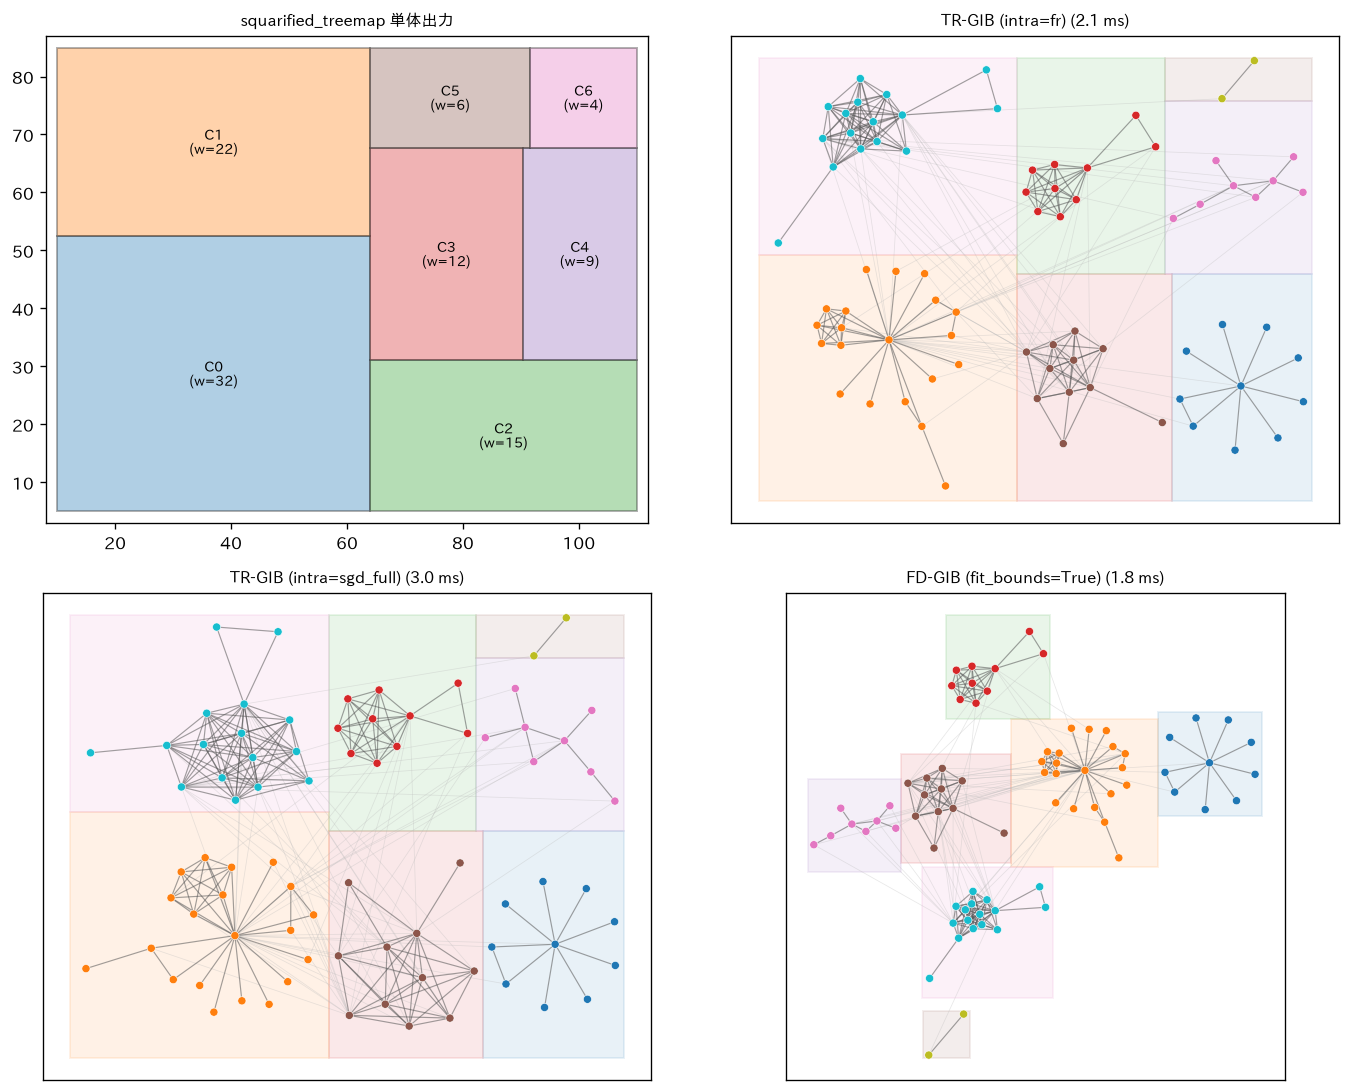

In [ ]:
\
# 1) Standalone squarified_treemap
weights = np.array([32.0, 22.0, 15.0, 12.0, 9.0, 6.0, 4.0])
rects = eg.squarified_treemap(weights, width=100.0, height=80.0, x=10.0, y=5.0)
print("squarified_treemap first 2 rows [x_min, x_max, y_min, y_max]:", rects[:2].tolist())

# 2) GroupInABoxSolver across box_mode and intra_mode on lesmis (with fit_bounds=True default vs False)
gib_configs = [
    ("treemap", "fr", True, "TR-GIB (intra=fr)"),
    ("treemap", "sgd_full", True, "TR-GIB (intra=sgd_full)"),
    ("treemap", "yifan_hu", True, "TR-GIB (intra=yifan_hu)"),
    ("force_directed", "fr", True, "FD-GIB (fit_bounds=True)"),
]
gib_results = []
for bmode, imode, fit_b, jp_title in gib_configs:
    lay = eg.Layout2d.init(g_lesmis.num_nodes, seed=42)
    t0 = time.perf_counter()
    gib = eg.GroupInABoxSolver(
        g_lesmis,
        lv_lm,
        box_mode=bmode,
        intra_mode=imode,
        total_width=100.0,
        total_height=80.0,
        box_padding=0.06,
        intra_iterations=100,
        fit_bounds=fit_b,
        seed=42,
    )
    gib.run(lay)
    ms = (time.perf_counter() - t0) * 1000.0
    boxes = gib.boxes()
    assert lay.is_all_finite()
    c_gib = lay.coords(copy=False)
    print(
        f"{jp_title:<25} {ms:5.1f} ms | num_boxes={len(boxes)} | "
        f"x=[{c_gib[:, 0].min():.1f}, {c_gib[:, 0].max():.1f}], y=[{c_gib[:, 1].min():.1f}, {c_gib[:, 1].max():.1f}]"
    )
    gib_results.append((jp_title, lay, boxes, ms))

fig, axes = plt.subplots(2, 2, figsize=(12, 9.2))

# Top-left: standalone squarified_treemap
ax0 = axes[0, 0]
cmap = plt.get_cmap("tab10")
for i, (x0, x1, y0, y1) in enumerate(rects):
    ax0.add_patch(
        Rectangle((x0, y0), x1 - x0, y1 - y0, facecolor=cmap(i % 10), alpha=0.35, edgecolor="#222222", linewidth=1.2)
    )
    ax0.text(0.5 * (x0 + x1), 0.5 * (y0 + y1), f"C{i}\n(w={weights[i]:.0f})", ha="center", va="center", fontsize=8.5)
ax0.set_xlim(8, 112)
ax0.set_ylim(3, 87)
ax0.set_aspect("equal")
ax0.set_title("squarified_treemap 単体出力", fontsize=9.5)

# Other 3 panels: TR-GIB (fr), TR-GIB (sgd_full), FD-GIB (fr)
for ax, (jp_title, lay, boxes, ms) in zip([axes[0, 1], axes[1, 0], axes[1, 1]], [gib_results[0], gib_results[1], gib_results[3]]):
    plot_gib_boxes(g_lesmis, lay, lv_lm, boxes, ax, title=f"{jp_title} ({ms:.1f} ms)")

plt.tight_layout()
plt.show()

\
## 5. クラスタ配置リファインメント (`ClusterRefineSolver`, `refine_cluster_layout`)

力学モデル等で得られた初期配置に対して、クラスタの分離度や面積忠実性を高める後処理を行います。

- `ClusterRefineSolver(labels, method="kmeans"|"hac", max_iterations=10, ...)` / `ClusterRefineSolver.from_graph(graph, labels, ...)`:  
  `"hac"` モードでは `.from_graph(...)`（または `refine_cluster_layout(..., graph=...)`）を用いると平均グラフ辺長 $\ell$ を移動ステップ幅として利用でき、グラフなしでは 1-NN 距離フォールバックが用いられます。
- 評価指標には `evaluate_metrics(..., labels=...)` が返す `MetricReport` の `cluster_area_faithfulness`, `distance_consistency` (`"dsc"`), `neighborhood_hit`, `silhouette_score` (`"silhouette"`) を用います。

ClusterRefineSolver (kmeans): num_clusters=7, last_moved=0
ClusterRefineSolver.from_graph (hac): num_clusters=7, last_moved=40
refine_cluster_layout (kmeans, graph=g_lesmis): total_moved=14

レイアウト                           G-CAF      DSC       NH  Silhouette
-------------------------------------------------------------------
リファイン前 (FA2)                   0.7850   0.9221   0.8516      0.4550
ClusterRefine (kmeans)         0.8449   1.0000   0.9295      0.5814
ClusterRefine.from_graph (hac)   0.3960   0.8961   0.9258      0.6047
refine_cluster_layout          0.8449   1.0000   0.9295      0.5814


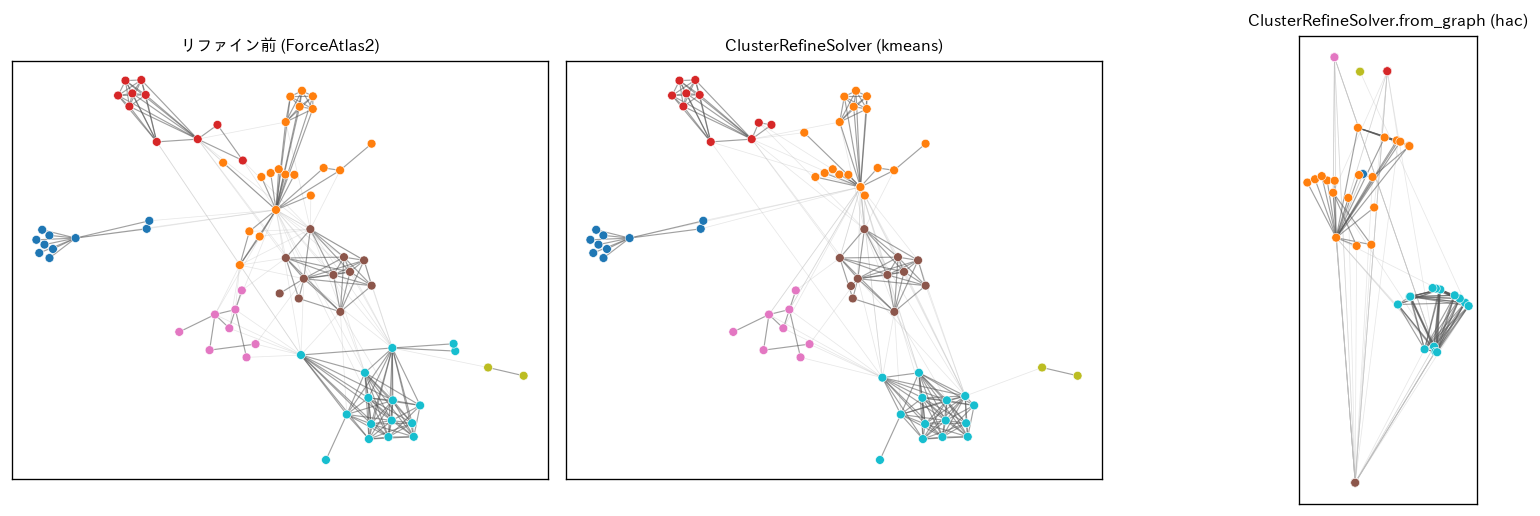

In [ ]:
\
# Compute initial ForceAtlas2 layout on lesmis
lay_fa2_lm = eg.Layout2d.init(g_lesmis.num_nodes, seed=42)
eg.ForceAtlas2Solver(g_lesmis, iterations=120, seed=42).run(lay_fa2_lm)

# 1) ClusterRefineSolver (kmeans)
lay_cr_km = eg.Layout2d.from_coords(lay_fa2_lm.copy_coords())
solver_km = eg.ClusterRefineSolver(lv_lm, method="kmeans", max_iterations=10, margin=0.25, seed=42)
solver_km.run(lay_cr_km)

# 2) ClusterRefineSolver.from_graph (hac)
lay_cr_hac = eg.Layout2d.from_coords(lay_fa2_lm.copy_coords())
solver_hac = eg.ClusterRefineSolver.from_graph(g_lesmis, lv_lm, method="hac", max_iterations=10, margin=0.25, seed=42)
solver_hac.run(lay_cr_hac)

# 3) Functional refine_cluster_layout (supports optional graph= for edge-length scaling)
lay_cr_fn = eg.Layout2d.from_coords(lay_fa2_lm.copy_coords())
total_moved = eg.refine_cluster_layout(lay_cr_fn, lv_lm, graph=g_lesmis, method="kmeans", max_iterations=10, margin=0.25, seed=42)

c_targets = ["cluster_area_faithfulness", "distance_consistency", "neighborhood_hit", "silhouette_score"]
print(f"ClusterRefineSolver (kmeans): num_clusters={solver_km.num_clusters}, last_moved={solver_km.last_moved_count}")
print(f"ClusterRefineSolver.from_graph (hac): num_clusters={solver_hac.num_clusters}, last_moved={solver_hac.last_moved_count}")
print(f"refine_cluster_layout (kmeans, graph=g_lesmis): total_moved={total_moved}\n")

print(f"{'レイアウト':<28} {'G-CAF':>8} {'DSC':>8} {'NH':>8} {'Silhouette':>11}")
print("-" * 67)
for label, lay in [
    ("リファイン前 (FA2)", lay_fa2_lm),
    ("ClusterRefine (kmeans)", lay_cr_km),
    ("ClusterRefine.from_graph (hac)", lay_cr_hac),
    ("refine_cluster_layout", lay_cr_fn),
]:
    m = eg.evaluate_metrics(g_lesmis, lay, c_targets, labels=lv_lm)
    print(f"{label:<28} {m.cluster_area_faithfulness:>8.4f} {m.distance_consistency:>8.4f} {m.neighborhood_hit:>8.4f} {m.silhouette_score:>11.4f}")

fig, axes = plt.subplots(1, 3, figsize=(14, 4.4))
plot_clustered_graph(g_lesmis, lay_fa2_lm, lv_lm, axes[0], title="リファイン前 (ForceAtlas2)")
plot_clustered_graph(g_lesmis, lay_cr_km, lv_lm, axes[1], title="ClusterRefineSolver (kmeans)")
plot_clustered_graph(g_lesmis, lay_cr_hac, lv_lm, axes[2], title="ClusterRefineSolver.from_graph (hac)")
plt.tight_layout()
plt.show()

\
## 6. 有向グラフの閉路除去・推移簡約・階層割り当て・分離制約付き Sugiyama レイアウト

有向グラフに対して Sugiyama 風の階層レイアウトを構築する一連のプリミティブを確認します。

1. `cycle_edges(g)` / `remove_cycles(g)`: 有向グラフから閉路をなす逆向き辺を検出し、**辺を反転（reverse）** した新しい DAG `CsrGraph` を返します（`directed=True` 必須）。
2. `transitive_reduction(g_dag)`: 元の到達関係を保ったまま冗長な推移辺を削除して最小 DAG を構築します（`generate_layered_dag` と組み合わせて効果を確認できます）。
3. `assign_layers(g_dag, method=...)`: `"longest_path"` と総辺長 $\sum (L[v] - L[u])$ を最小化する `"network_simplex"` を比較します。
4. `SeparationConstraint(left, right, gap)` / `generate_layered_constraints(g_dag, layers, min_layer_distance=...)`: 階層間ギャップ制約を生成します。
5. `project_1d(coords, constraints)` / `project_layout_axis(layout, axis, constraints)`:  
   ※ `project_1d` は書き込み可能な 1D NumPy 配列を**インプレースで直接書き換え、`None` を返します**。
6. **制約付き SGD への組み込み**: 有向 DAG そのままでは `SgdSolver.full` の有向 BFS が非到達ペアを `inf` 扱いして X 座標が潰れるため、**無向化した骨格グラフを `SgdSolver.full` に渡し、ステップごとに有向階層から生成した `project_layout_axis(lay, 1, constraints)` を適用**します。

cycle_edges detected: [[4, 1], [8, 0]] -> after remove_cycles: 0 cycles
generate_layered_dag (4x5): edges=103 -> transitive_reduction: edges=55 (-46.6%)
assign_layers longest_path:    [0, 1, 2, 3, 4, 0, 0, 1, 3] (total span=27)
assign_layers network_simplex: [0, 1, 2, 3, 4, 3, 2, 1, 3] (total span=20)
SeparationConstraint[0]: left=0, right=1, gap=1.5
project_1d mutated arr_1d in-place=[-0.667, 0.833, 2.333], return=None
Constrained SGD (longest_path):    constraints=13, max_violation=0.00e+00
Constrained SGD (network_simplex): constraints=13, max_violation=2.22e-16


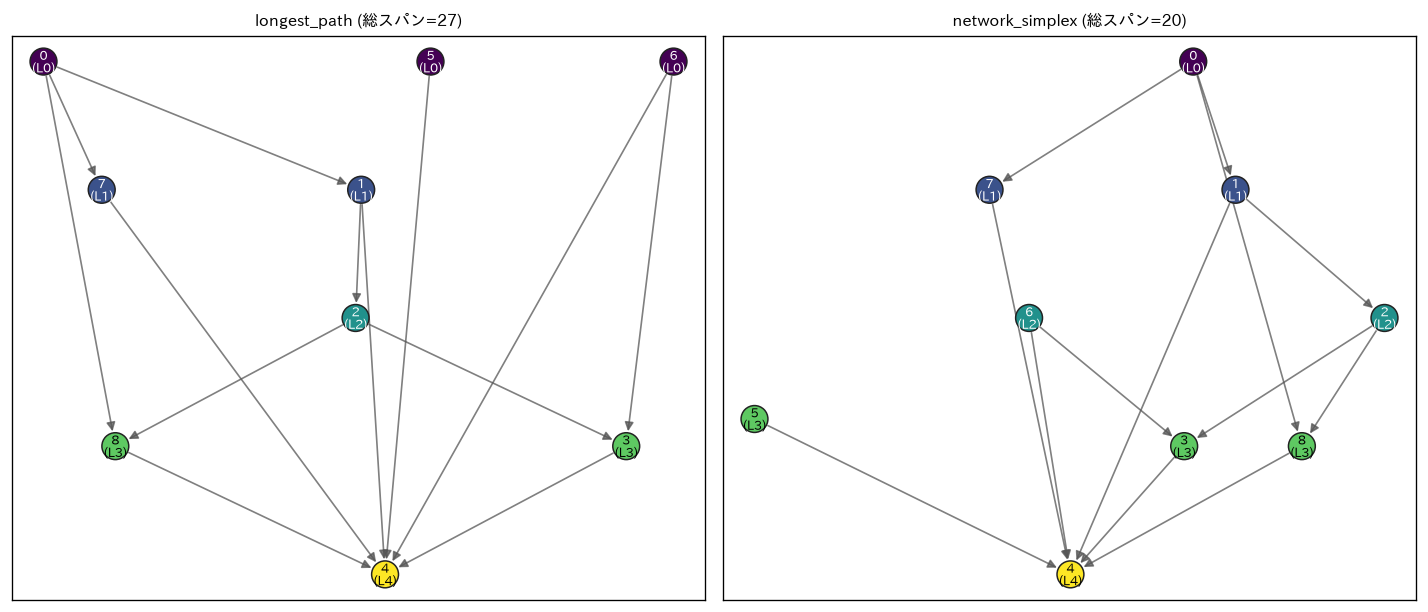

In [ ]:
\
# 1) Build a 9-node directed graph with unequal path lengths and 2 cycle-closing back-edges
dir_edges = [
    (0, 1), (1, 2), (2, 3), (3, 4),
    (5, 4), (6, 3), (6, 4), (0, 7), (7, 4), (2, 8), (8, 4),
    (8, 0), (4, 1),  # back-edges creating cycles
]
g_cyclic = eg.CsrGraph.from_edge_list(9, dir_edges, directed=True)
ce = eg.cycle_edges(g_cyclic)
g_dag = eg.remove_cycles(g_cyclic)
assert len(eg.cycle_edges(g_dag)) == 0
print(f"cycle_edges detected: {ce.tolist()} -> after remove_cycles: {len(eg.cycle_edges(g_dag))} cycles")

# 1b) Synthetic layered DAG + transitive_reduction
g_gen_dag = eg.generate_layered_dag(num_layers=4, nodes_per_layer=5, edge_prob=0.65, seed=42)
g_gen_tr = eg.transitive_reduction(g_gen_dag)
print(
    f"generate_layered_dag (4x5): edges={g_gen_dag.num_edges} -> "
    f"transitive_reduction: edges={g_gen_tr.num_edges} "
    f"(-{100.0 * (1.0 - g_gen_tr.num_edges / max(1, g_gen_dag.num_edges)):.1f}%)"
)

# 2) Compare longest_path vs network_simplex layering
layers_lp = eg.assign_layers(g_dag, method="longest_path")
layers_ns = eg.assign_layers(g_dag, method="network_simplex")


def total_edge_span(g: eg.CsrGraph, layers: np.ndarray) -> int:
    indptr, indices = g.indptr(), g.indices()
    return int(sum(int(layers[int(v)]) - int(layers[u]) for u in range(g.num_nodes) for v in indices[int(indptr[u]) : int(indptr[u + 1])]))


print(f"assign_layers longest_path:    {layers_lp.tolist()} (total span={total_edge_span(g_dag, layers_lp)})")
print(f"assign_layers network_simplex: {layers_ns.tolist()} (total span={total_edge_span(g_dag, layers_ns)})")

# 3) Demonstrate SeparationConstraint + project_1d (mutates writable 1D NumPy array in-place, returns None)
arr_1d = np.array([2.0, 0.5, 0.0], dtype=np.float64)
manual_c = [eg.SeparationConstraint(0, 1, 1.5), eg.SeparationConstraint(1, 2, 1.5)]
ret_1d = eg.project_1d(arr_1d, manual_c)
assert ret_1d is None
print(f"SeparationConstraint[0]: left={manual_c[0].left}, right={manual_c[0].right}, gap={manual_c[0].gap}")
print(f"project_1d mutated arr_1d in-place={np.round(arr_1d, 3).tolist()}, return={ret_1d}")

# 4) Build undirected skeleton of g_dag for SgdSolver.full + project_layout_axis on Y (axis=1)
indptr_d, indices_d = g_dag.indptr(), g_dag.indices()
undir_edges = [(u, int(v)) for u in range(g_dag.num_nodes) for v in indices_d[int(indptr_d[u]) : int(indptr_d[u + 1])]]
g_dag_undir = eg.CsrGraph.from_edge_list(g_dag.num_nodes, undir_edges, directed=False)


def solve_constrained_dag(layers: np.ndarray):
    constraints = eg.generate_layered_constraints(g_dag, layers, min_layer_distance=1.5)
    lay = eg.Layout2d.init(g_dag.num_nodes, seed=42)
    sgd = eg.SgdSolver.full(g_dag_undir, iterations=30, seed=42)
    while not sgd.is_finished:
        sgd.step(lay)
        eg.project_layout_axis(lay, 1, constraints)
    coords = lay.coords(copy=False)
    max_viol = max(max(0.0, (coords[c.left, 1] + c.gap) - coords[c.right, 1]) for c in constraints)
    return lay, constraints, max_viol


lay_lp, c_lp, viol_lp = solve_constrained_dag(layers_lp)
lay_ns, c_ns, viol_ns = solve_constrained_dag(layers_ns)
print(f"Constrained SGD (longest_path):    constraints={len(c_lp)}, max_violation={viol_lp:.2e}")
print(f"Constrained SGD (network_simplex): constraints={len(c_ns)}, max_violation={viol_ns:.2e}")

fig, axes = plt.subplots(1, 2, figsize=(12, 5.2))
plot_dag_layered(g_dag, lay_lp, layers_lp, axes[0], title=f"longest_path (総スパン={total_edge_span(g_dag, layers_lp)})")
plot_dag_layered(g_dag, lay_ns, layers_ns, axes[1], title=f"network_simplex (総スパン={total_edge_span(g_dag, layers_ns)})")
plt.tight_layout()
plt.show()